# Lab 1 – Spectral analysis of deterministic signals
### Signal synthesis with the IDFT in matrix notation — all 15 variants

| | |
|---|---|
| **Author** | Radosław Skrzypczyński — Informatyka II st., niestacjonarne, 1 sem., Gr. 2 |
| **Course** | Digital Signal Processing — prof. dr hab. Vasyl Martsenyuk |
| **Repository** | https://github.com/Slayzerus/dsp-lab1 |

**Task (Sec. 7 of the lab instructions).** Synthesize a discrete-time signal by using the IDFT in matrix
notation for different values of N. Show the matrices **W** and **K**. Plot the signal synthesized.
The DFT coefficient vectors x_μ of the variants are given in the instructions. **All 15 variants are computed.**

**Contents.** 1 Theory · 2 Helper functions · 3 Validation against the instructions · 4 Variants ·
5 Matrices K and W · 6 Synthesis for all variants and several N · 7 Plots of the synthesized signals ·
8 Effect of N · 9 Interpretation · 10 Conclusions

In [1]:
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
from numpy.fft import ifft
from IPython.display import display

print(f"Python {platform.python_version()} | numpy {np.__version__} | matplotlib {matplotlib.__version__} | "
      f"pandas {pd.__version__}")

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
pd.options.display.precision = 3
pd.options.display.width = 200

Python 3.14.2 | numpy 2.4.1 | matplotlib 3.10.8 | pandas 3.0.6


## 1. Theory

* **DFT pair** (instructions, eq. 1–2), 0 ≤ k, μ ≤ N − 1:
  X[μ] = Σₖ x[k]·e^(−j2πkμ/N)  and  x[k] = (1/N)·Σ_μ X[μ]·e^(+j2πkμ/N).
  This is the convention of `numpy.fft.fft` / `numpy.fft.ifft`.
* **Matrix notation** (eq. 3–6): with the column vectors x_k = (x[0], …, x[N−1])ᵀ and x_μ = (X[0], …, X[N−1])ᵀ

  **DFT:** x_μ = W*·x_k  **IDFT:** x_k = (1/N)·W·x_μ
* **Fourier matrix** (eq. 7–9): W = e^(+j2π/N ⊙ K) (element-wise), i.e. W[k, μ] = W_N^(k·μ) with the twiddle
  factor W_N = e^(+j2π/N), and K is the outer product K = (0, 1, …, N−1)ᵀ·(0, 1, …, N−1), so K[k, μ] = k·μ.
  Because W_N^N = 1, only the exponent (k·μ mod N) matters.
* **Properties** (eq. 11–14): W is symmetric and W⁻¹ = W^H/N = W*/N, so W/√N is unitary. The columns
  w_μ[k] = cos(2πkμ/N) + j·sin(2πkμ/N) are the orthogonal DFT eigensignals with the digital frequencies
  Ω_μ = 2πμ/N. The IDFT therefore synthesizes x_k as a **linear combination of the columns of W**, weighted by
  X[μ]/N (signal synthesis = forward problem; the DFT is the inverse problem, signal analysis).
* **Different N.** A vector of length N₀ is used with N = N₀ and with longer IDFTs N = 2N₀ and 4N₀ by appending
  zeros (X[μ] = 0 for N₀ ≤ μ < N). Every coefficient keeps its index μ, but its digital frequency becomes 2πμ/N.

In [2]:
# Plot style: the same as in the Lab 2 (windowing) notebook, so that all reports look alike.
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": [f for f in ("Segoe UI", "DejaVu Sans") if f in _fonts] or ["sans-serif"],
    "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 8, "legend.labelcolor": INK2,
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "mathtext.fontset": "dejavusans", "figure.titlesize": 10.5, "figure.titleweight": "semibold",
})
C_RE, C_IM = "#2a78d6", "#eb6834"          # real part / imaginary part, fixed in every figure
DIVERGING = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f7f6f2", "#2a78d6"])


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()


def stem(ax, k, y, color, label=None, ms=4.0):
    """Thin stem plot: marker on a hairline stem, no baseline."""
    markers, stems, base = ax.stem(k, y, linefmt="-", markerfmt="o", basefmt=" ", label=label)
    plt.setp(stems, color=color, linewidth=0.9)
    plt.setp(markers, color=color, markersize=ms, markeredgecolor="white", markeredgewidth=0.5)
    return markers

## 2. Helper functions

The functions follow the template notebook of the course (`build_K_W`, `idft_matrix`, `pad_or_trim_X`).
K is built explicitly as the outer product of a column and a row vector, as required by the task.

In [3]:
def build_K(N):
    """Index matrix K = (0..N-1)^T (0..N-1): K[k, mu] = k*mu (outer product, eq. 9)."""
    k = np.arange(N).reshape(-1, 1)      # column vector (N x 1)
    mu = np.arange(N).reshape(1, -1)     # row vector (1 x N)
    return k @ mu


def build_W(N):
    """Fourier matrix W = exp(+j 2pi/N (.) K) (eq. 7)."""
    return np.exp(+1j * 2*np.pi/N * build_K(N))


def pad(X, N):
    """DFT vector of length N: X[mu] = 0 for mu >= len(X) (zero-padding of the spectrum)."""
    X = np.asarray(X, dtype=complex).ravel()
    if N < X.size:
        raise ValueError("N must not be smaller than the given vector")
    out = np.zeros(N, dtype=complex)
    out[:X.size] = X
    return out


def idft_matrix(X, N=None):
    """IDFT in matrix notation: x_k = (1/N) W x_mu (eq. 6)."""
    X = pad(X, len(X) if N is None else N)
    return build_W(X.size) @ X / X.size


def dft_matrix(x):
    """DFT in matrix notation: x_mu = W* x_k (eq. 5)."""
    return np.conj(build_W(x.size)) @ x


def clean(a, d=3):
    """Round for display and remove negative zeros."""
    return np.round(a, d) + 0.0

## 3. Validation against the instructions

The helpers reproduce the matrices K and W for N = 4 given in eq. (10) and the initial example of Sec. 6:
N = 8, x_μ = [8, 2, 4, 0, 0, 0, 0, 0]ᵀ (a DC value plus the first and the second eigenfrequency).

In [4]:
K4_expected = np.array([[0, 0, 0, 0], [0, 1, 2, 3], [0, 2, 4, 6], [0, 3, 6, 9]])
W4_expected = np.array([[1, 1, 1, 1], [1, 1j, -1, -1j], [1, -1, 1, -1], [1, -1j, -1, 1j]])

X_ex = np.array([8, 2, 4, 0, 0, 0, 0, 0])
x_ex = idft_matrix(X_ex)
W8 = build_W(8)
U8 = W8/np.sqrt(8)
validation = {
    "K for N = 4 equals eq. (10)": np.array_equal(build_K(4), K4_expected),
    "W for N = 4 equals eq. (10)": np.allclose(build_W(4), W4_expected),
    "W is symmetric (W = Wᵀ)": np.allclose(W8, W8.T),
    "W⁻¹ = W*/N (eq. 11)": np.allclose(np.linalg.inv(W8), np.conj(W8)/8),
    "W/√N is unitary (eq. 14)": np.allclose(U8.conj().T @ U8, np.eye(8)),
    "eigensignals orthogonal: w₀ᴴw₁ = 0, w₁ᴴw₁ = N": np.isclose(np.vdot(W8[:, 0], W8[:, 1]), 0)
                                                    and np.isclose(np.vdot(W8[:, 1], W8[:, 1]), 8),
    "IDFT (matrix) equals numpy.fft.ifft": np.allclose(x_ex, ifft(X_ex)),
    "DFT (matrix) of x_k returns x_μ": np.allclose(dft_matrix(x_ex), X_ex),
    "x_k = (1/N)(8·w₀ + 2·w₁ + 4·w₂)": np.allclose(x_ex, (8*W8[:, 0] + 2*W8[:, 1] + 4*W8[:, 2])/8),
    "DC value: mean(x_k) = X[0]/N = 1": np.isclose(x_ex.mean(), 1),
}
display(pd.Series(validation, name="holds").to_frame())
assert all(validation.values())

print("K (N = 4):\n", build_K(4))
print("W (N = 4):\n", clean(build_W(4)))
print("x_k of the example (N = 8):\n", clean(x_ex))

,holds
K for N = 4 equals eq. (10),True
W for N = 4 equals eq. (10),True
W is symmetric (W = Wᵀ),True
W⁻¹ = W*/N (eq. 11),True
W/√N is unitary (eq. 14),True
"eigensignals orthogonal: w₀ᴴw₁ = 0, w₁ᴴw₁ = N",True
IDFT (matrix) equals numpy.fft.ifft,True
DFT (matrix) of x_k returns x_μ,True
x_k = (1/N)(8·w₀ + 2·w₁ + 4·w₂),True
DC value: mean(x_k) = X[0]/N = 1,True


K (N = 4):
 [[0 0 0 0]
 [0 1 2 3]
 [0 2 4 6]
 [0 3 6 9]]
W (N = 4):
 [[ 1.+0.j  1.+0.j  1.+0.j  1.+0.j]
 [ 1.+0.j  0.+1.j -1.+0.j  0.-1.j]
 [ 1.+0.j -1.+0.j  1.+0.j -1.+0.j]
 [ 1.+0.j  0.-1.j -1.+0.j  0.+1.j]]
x_k of the example (N = 8):
 [1.75 +0.j    1.177+0.677j 0.5  +0.25j  0.823-0.323j 1.25 +0.j
 0.823+0.323j 0.5  -0.25j  1.177-0.677j]


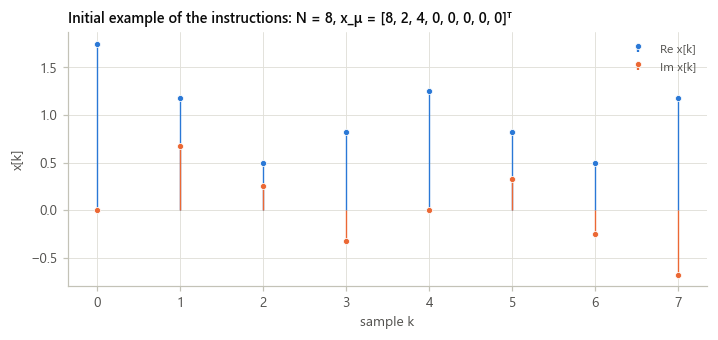

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.0))
k8 = np.arange(8)
stem(ax, k8, x_ex.real, C_RE, "Re x[k]")
stem(ax, k8, x_ex.imag, C_IM, "Im x[k]")
ax.set(xlabel="sample k", ylabel="x[k]", xticks=k8)
ax.set_title("Initial example of the instructions: N = 8, x_μ = [8, 2, 4, 0, 0, 0, 0, 0]ᵀ")
ax.legend(loc="upper right")
save(fig, "fig01_example_N8")

## 4. Variants

The 15 vectors x_μ are taken from Sec. 7 of the instructions. Several variants are identical, so the 15 variants
contain **9 different vectors (groups G1–G9)**. All variants are still computed individually and the identity of
the results within a group is asserted in Section 6.

In [6]:
VARIANTS = {
    1: [6, 2, 4, 3, 4, 5, 0, 0, 0, 0],
    2: [10, 5, 6, 6, 2, 4, 3, 4, 5, 0, 0, 0, 0],
    3: [6, 2, 4, 3, 4, 5, 0, 0, 0, 0],
    4: [6, 2, 4, 3, 4, 5, 0, 0, 0],
    5: [6, 4, 4, 5, 3, 4, 5, 0, 0, 0, 0],
    6: [7, 2, 4, 3, 4, 5, 0, 0, 0, 0],
    7: [6, 8, 2, 4, 3, 4, 5, 0, 0, 0],
    8: [6, 2, 4, 4, 4, 5, 0, 0, 0, 0],
    9: [6, 5, 4, 3, 4, 5, 0, 0, 0, 0],
    10: [6, 2, 4, 3, 4, 4, 0, 0, 0, 0],
    11: [6, 2, 4, 3, 4, 5, 0, 0, 0, 0],
    12: [10, 5, 6, 6, 2, 4, 3, 4, 5, 0, 0, 0, 0],
    13: [6, 2, 4, 3, 4, 5, 0, 0, 0, 0],
    14: [6, 2, 4, 3, 4, 5, 0, 0, 0],
    15: [6, 4, 4, 5, 3, 4, 5, 0, 0, 0, 0],
}
VARIANTS = {no: np.array(v, dtype=float) for no, v in VARIANTS.items()}

GROUPS = {}                                   # "G1" -> [variant numbers]
_seen = {}
for no, X in VARIANTS.items():
    key = tuple(X)
    if key not in _seen:
        _seen[key] = f"G{len(_seen) + 1}"
    GROUPS.setdefault(_seen[key], []).append(no)
GROUP_OF = {no: g for g, nos in GROUPS.items() for no in nos}

table = pd.DataFrame([{
    "No": no, "x_μ": "[" + ", ".join(f"{v:g}" for v in X) + "]ᵀ", "N₀ = length": X.size,
    "non-zero X[μ]": int(np.count_nonzero(X)), "highest non-zero μ": int(np.flatnonzero(X).max()),
    "Σ X[μ]": X.sum(), "group": GROUP_OF[no]} for no, X in VARIANTS.items()]).set_index("No")
display(table)
display(pd.DataFrame({"variants": {g: ", ".join(map(str, nos)) for g, nos in GROUPS.items()}}))
N0_SET = sorted({X.size for X in VARIANTS.values()})
print("Lengths N₀ that occur:", N0_SET)

,x_μ,N₀ = length,non-zero X[μ],highest non-zero μ,Σ X[μ],group
No,,,,,,
1,"[6, 2, 4, 3, 4, 5, 0, 0, 0, 0]ᵀ",10,6,5,24.0,G1
2,"[10, 5, 6, 6, 2, 4, 3, 4, 5, 0, 0, 0, 0]ᵀ",13,9,8,45.0,G2
3,"[6, 2, 4, 3, 4, 5, 0, 0, 0, 0]ᵀ",10,6,5,24.0,G1
4,"[6, 2, 4, 3, 4, 5, 0, 0, 0]ᵀ",9,6,5,24.0,G3
5,"[6, 4, 4, 5, 3, 4, 5, 0, 0, 0, 0]ᵀ",11,7,6,31.0,G4
6,"[7, 2, 4, 3, 4, 5, 0, 0, 0, 0]ᵀ",10,6,5,25.0,G5
7,"[6, 8, 2, 4, 3, 4, 5, 0, 0, 0]ᵀ",10,7,6,32.0,G6
8,"[6, 2, 4, 4, 4, 5, 0, 0, 0, 0]ᵀ",10,6,5,25.0,G7
9,"[6, 5, 4, 3, 4, 5, 0, 0, 0, 0]ᵀ",10,6,5,27.0,G8


,variants
G1,"1, 3, 11, 13"
G2,"2, 12"
G3,"4, 14"
G4,"5, 15"
G5,6
G6,7
G7,8
G8,9
G9,10


Lengths N₀ that occur: [9, 10, 11, 13]


* All vectors are **real and non-negative**, and only the first 6–9 coefficients are non-zero; the trailing zeros
  only fix the IDFT length N₀ ∈ {9, 10, 11, 13}.
* G1 (variants 1, 3, 11, 13) and G3 (variants 4, 14) have the **same non-zero coefficients** [6, 2, 4, 3, 4, 5]
  and differ only in N₀ (10 vs 9).
* The matrices K and W depend **only on N**, not on the coefficients, so for N = N₀ only four different pairs
  (K, W) are needed for all 15 variants.

## 5. Matrices K and W

The full matrices are shown for every N₀ that occurs (N = 9, 10, 11, 13). W is complex, so its real part
Re W[k, μ] = cos(2πkμ/N) and its imaginary part Im W[k, μ] = sin(2πkμ/N) are listed as two tables
(3 decimals). The rows are indexed by the time index k, the columns by the frequency index μ.

In [7]:
def show_K_W(N):
    idx_k, idx_mu = pd.Index(range(N), name="k \\ μ"), pd.Index(range(N), name="")
    K, W = build_K(N), build_W(N)
    print(f"N = {N}:  K = outer(k, μ), shape {K.shape};  W = exp(+j2π/{N}·K), shape {W.shape}")
    print("Matrix K:")
    display(pd.DataFrame(K, index=idx_k, columns=idx_mu))
    print("Matrix W, real part Re W = cos(2π/N·K):")
    display(pd.DataFrame(clean(W.real), index=idx_k, columns=idx_mu))
    print("Matrix W, imaginary part Im W = sin(2π/N·K):")
    display(pd.DataFrame(clean(W.imag), index=idx_k, columns=idx_mu))

### 5.1 N = 10 (variants 1, 3, 6, 7, 8, 9, 10, 11, 13)

In [8]:
show_K_W(10)

N = 10:  K = outer(k, μ), shape (10, 10);  W = exp(+j2π/10·K), shape (10, 10)
Matrix K:


,0,1,2,3,4,5,6,7,8,9
k \ μ,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0
1,0,1,2,3,4,5,6,7,8,9
2,0,2,4,6,8,10,12,14,16,18
3,0,3,6,9,12,15,18,21,24,27
4,0,4,8,12,16,20,24,28,32,36
5,0,5,10,15,20,25,30,35,40,45
6,0,6,12,18,24,30,36,42,48,54
7,0,7,14,21,28,35,42,49,56,63
8,0,8,16,24,32,40,48,56,64,72


Matrix W, real part Re W = cos(2π/N·K):


,0,1,2,3,4,5,6,7,8,9
k \ μ,,,,,,,,,,
0,1.0,1.000,1.000,1.000,1.000,1.0,1.000,1.000,1.000,1.000
1,1.0,0.809,0.309,-0.309,-0.809,-1.0,-0.809,-0.309,0.309,0.809
2,1.0,0.309,-0.809,-0.809,0.309,1.0,0.309,-0.809,-0.809,0.309
3,1.0,-0.309,-0.809,0.809,0.309,-1.0,0.309,0.809,-0.809,-0.309
4,1.0,-0.809,0.309,0.309,-0.809,1.0,-0.809,0.309,0.309,-0.809
5,1.0,-1.000,1.000,-1.000,1.000,-1.0,1.000,-1.000,1.000,-1.000
6,1.0,-0.809,0.309,0.309,-0.809,1.0,-0.809,0.309,0.309,-0.809
7,1.0,-0.309,-0.809,0.809,0.309,-1.0,0.309,0.809,-0.809,-0.309
8,1.0,0.309,-0.809,-0.809,0.309,1.0,0.309,-0.809,-0.809,0.309


Matrix W, imaginary part Im W = sin(2π/N·K):


,0,1,2,3,4,5,6,7,8,9
k \ μ,,,,,,,,,,
0,0.0,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000
1,0.0,0.588,0.951,0.951,0.588,0.0,-0.588,-0.951,-0.951,-0.588
2,0.0,0.951,0.588,-0.588,-0.951,0.0,0.951,0.588,-0.588,-0.951
3,0.0,0.951,-0.588,-0.588,0.951,0.0,-0.951,0.588,0.588,-0.951
4,0.0,0.588,-0.951,0.951,-0.588,0.0,0.588,-0.951,0.951,-0.588
5,0.0,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000
6,0.0,-0.588,0.951,-0.951,0.588,0.0,-0.588,0.951,-0.951,0.588
7,0.0,-0.951,0.588,0.588,-0.951,0.0,0.951,-0.588,-0.588,0.951
8,0.0,-0.951,-0.588,0.588,0.951,0.0,-0.951,-0.588,0.588,0.951


### 5.2 N = 13 (variants 2, 12)

In [9]:
show_K_W(13)

N = 13:  K = outer(k, μ), shape (13, 13);  W = exp(+j2π/13·K), shape (13, 13)
Matrix K:


,0,1,2,3,4,5,6,7,8,9,10,11,12
k \ μ,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,2,3,4,5,6,7,8,9,10,11,12
2,0,2,4,6,8,10,12,14,16,18,20,22,24
3,0,3,6,9,12,15,18,21,24,27,30,33,36
4,0,4,8,12,16,20,24,28,32,36,40,44,48
5,0,5,10,15,20,25,30,35,40,45,50,55,60
6,0,6,12,18,24,30,36,42,48,54,60,66,72
7,0,7,14,21,28,35,42,49,56,63,70,77,84
8,0,8,16,24,32,40,48,56,64,72,80,88,96


Matrix W, real part Re W = cos(2π/N·K):


,0,1,2,3,4,5,6,7,8,9,10,11,12
k \ μ,,,,,,,,,,,,,
0,1.0,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
1,1.0,0.885,0.568,0.121,-0.355,-0.749,-0.971,-0.971,-0.749,-0.355,0.121,0.568,0.885
2,1.0,0.568,-0.355,-0.971,-0.749,0.121,0.885,0.885,0.121,-0.749,-0.971,-0.355,0.568
3,1.0,0.121,-0.971,-0.355,0.885,0.568,-0.749,-0.749,0.568,0.885,-0.355,-0.971,0.121
4,1.0,-0.355,-0.749,0.885,0.121,-0.971,0.568,0.568,-0.971,0.121,0.885,-0.749,-0.355
5,1.0,-0.749,0.121,0.568,-0.971,0.885,-0.355,-0.355,0.885,-0.971,0.568,0.121,-0.749
6,1.0,-0.971,0.885,-0.749,0.568,-0.355,0.121,0.121,-0.355,0.568,-0.749,0.885,-0.971
7,1.0,-0.971,0.885,-0.749,0.568,-0.355,0.121,0.121,-0.355,0.568,-0.749,0.885,-0.971
8,1.0,-0.749,0.121,0.568,-0.971,0.885,-0.355,-0.355,0.885,-0.971,0.568,0.121,-0.749


Matrix W, imaginary part Im W = sin(2π/N·K):


,0,1,2,3,4,5,6,7,8,9,10,11,12
k \ μ,,,,,,,,,,,,,
0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.0,0.465,0.823,0.993,0.935,0.663,0.239,-0.239,-0.663,-0.935,-0.993,-0.823,-0.465
2,0.0,0.823,0.935,0.239,-0.663,-0.993,-0.465,0.465,0.993,0.663,-0.239,-0.935,-0.823
3,0.0,0.993,0.239,-0.935,-0.465,0.823,0.663,-0.663,-0.823,0.465,0.935,-0.239,-0.993
4,0.0,0.935,-0.663,-0.465,0.993,-0.239,-0.823,0.823,0.239,-0.993,0.465,0.663,-0.935
5,0.0,0.663,-0.993,0.823,-0.239,-0.465,0.935,-0.935,0.465,0.239,-0.823,0.993,-0.663
6,0.0,0.239,-0.465,0.663,-0.823,0.935,-0.993,0.993,-0.935,0.823,-0.663,0.465,-0.239
7,0.0,-0.239,0.465,-0.663,0.823,-0.935,0.993,-0.993,0.935,-0.823,0.663,-0.465,0.239
8,0.0,-0.663,0.993,-0.823,0.239,0.465,-0.935,0.935,-0.465,-0.239,0.823,-0.993,0.663


### 5.3 N = 9 (variants 4, 14)

In [10]:
show_K_W(9)

N = 9:  K = outer(k, μ), shape (9, 9);  W = exp(+j2π/9·K), shape (9, 9)
Matrix K:


,0,1,2,3,4,5,6,7,8
k \ μ,,,,,,,,,
0,0,0,0,0,0,0,0,0,0
1,0,1,2,3,4,5,6,7,8
2,0,2,4,6,8,10,12,14,16
3,0,3,6,9,12,15,18,21,24
4,0,4,8,12,16,20,24,28,32
5,0,5,10,15,20,25,30,35,40
6,0,6,12,18,24,30,36,42,48
7,0,7,14,21,28,35,42,49,56
8,0,8,16,24,32,40,48,56,64


Matrix W, real part Re W = cos(2π/N·K):


,0,1,2,3,4,5,6,7,8
k \ μ,,,,,,,,,
0,1.0,1.000,1.000,1.0,1.000,1.000,1.0,1.000,1.000
1,1.0,0.766,0.174,-0.5,-0.940,-0.940,-0.5,0.174,0.766
2,1.0,0.174,-0.940,-0.5,0.766,0.766,-0.5,-0.940,0.174
3,1.0,-0.500,-0.500,1.0,-0.500,-0.500,1.0,-0.500,-0.500
4,1.0,-0.940,0.766,-0.5,0.174,0.174,-0.5,0.766,-0.940
5,1.0,-0.940,0.766,-0.5,0.174,0.174,-0.5,0.766,-0.940
6,1.0,-0.500,-0.500,1.0,-0.500,-0.500,1.0,-0.500,-0.500
7,1.0,0.174,-0.940,-0.5,0.766,0.766,-0.5,-0.940,0.174
8,1.0,0.766,0.174,-0.5,-0.940,-0.940,-0.5,0.174,0.766


Matrix W, imaginary part Im W = sin(2π/N·K):


,0,1,2,3,4,5,6,7,8
k \ μ,,,,,,,,,
0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.0,0.643,0.985,0.866,0.342,-0.342,-0.866,-0.985,-0.643
2,0.0,0.985,0.342,-0.866,-0.643,0.643,0.866,-0.342,-0.985
3,0.0,0.866,-0.866,0.000,0.866,-0.866,0.000,0.866,-0.866
4,0.0,0.342,-0.643,0.866,-0.985,0.985,-0.866,0.643,-0.342
5,0.0,-0.342,0.643,-0.866,0.985,-0.985,0.866,-0.643,0.342
6,0.0,-0.866,0.866,0.000,-0.866,0.866,0.000,-0.866,0.866
7,0.0,-0.985,-0.342,0.866,0.643,-0.643,-0.866,0.342,0.985
8,0.0,-0.643,-0.985,-0.866,-0.342,0.342,0.866,0.985,0.643


### 5.4 N = 11 (variants 5, 15)

In [11]:
show_K_W(11)

N = 11:  K = outer(k, μ), shape (11, 11);  W = exp(+j2π/11·K), shape (11, 11)
Matrix K:


,0,1,2,3,4,5,6,7,8,9,10
k \ μ,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,2,3,4,5,6,7,8,9,10
2,0,2,4,6,8,10,12,14,16,18,20
3,0,3,6,9,12,15,18,21,24,27,30
4,0,4,8,12,16,20,24,28,32,36,40
5,0,5,10,15,20,25,30,35,40,45,50
6,0,6,12,18,24,30,36,42,48,54,60
7,0,7,14,21,28,35,42,49,56,63,70
8,0,8,16,24,32,40,48,56,64,72,80


Matrix W, real part Re W = cos(2π/N·K):


,0,1,2,3,4,5,6,7,8,9,10
k \ μ,,,,,,,,,,,
0,1.0,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
1,1.0,0.841,0.415,-0.142,-0.655,-0.959,-0.959,-0.655,-0.142,0.415,0.841
2,1.0,0.415,-0.655,-0.959,-0.142,0.841,0.841,-0.142,-0.959,-0.655,0.415
3,1.0,-0.142,-0.959,0.415,0.841,-0.655,-0.655,0.841,0.415,-0.959,-0.142
4,1.0,-0.655,-0.142,0.841,-0.959,0.415,0.415,-0.959,0.841,-0.142,-0.655
5,1.0,-0.959,0.841,-0.655,0.415,-0.142,-0.142,0.415,-0.655,0.841,-0.959
6,1.0,-0.959,0.841,-0.655,0.415,-0.142,-0.142,0.415,-0.655,0.841,-0.959
7,1.0,-0.655,-0.142,0.841,-0.959,0.415,0.415,-0.959,0.841,-0.142,-0.655
8,1.0,-0.142,-0.959,0.415,0.841,-0.655,-0.655,0.841,0.415,-0.959,-0.142


Matrix W, imaginary part Im W = sin(2π/N·K):


,0,1,2,3,4,5,6,7,8,9,10
k \ μ,,,,,,,,,,,
0,0.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0.0,0.541,0.910,0.990,0.756,0.282,-0.282,-0.756,-0.990,-0.910,-0.541
2,0.0,0.910,0.756,-0.282,-0.990,-0.541,0.541,0.990,0.282,-0.756,-0.910
3,0.0,0.990,-0.282,-0.910,0.541,0.756,-0.756,-0.541,0.910,0.282,-0.990
4,0.0,0.756,-0.990,0.541,0.282,-0.910,0.910,-0.282,-0.541,0.990,-0.756
5,0.0,0.282,-0.541,0.756,-0.910,0.990,-0.990,0.910,-0.756,0.541,-0.282
6,0.0,-0.282,0.541,-0.756,0.910,-0.990,0.990,-0.910,0.756,-0.541,0.282
7,0.0,-0.756,0.990,-0.541,-0.282,0.910,-0.910,0.282,0.541,-0.990,0.756
8,0.0,-0.990,0.282,0.910,-0.541,-0.756,0.756,0.541,-0.910,-0.282,0.990


### 5.5 Structure of K and W for the different N used in the synthesis

For variant 1 the synthesis uses N = 10, 20 and 40. The figure shows K, the effective twiddle exponent K mod N,
Re W and Im W. Row 0 and column 0 of W are all ones (μ = 0 is the DC eigensignal, k = 0 is the first sample);
column μ is a cosine (real part) and a sine (imaginary part) with exactly μ periods in N samples; the matrices are
symmetric about the main diagonal.

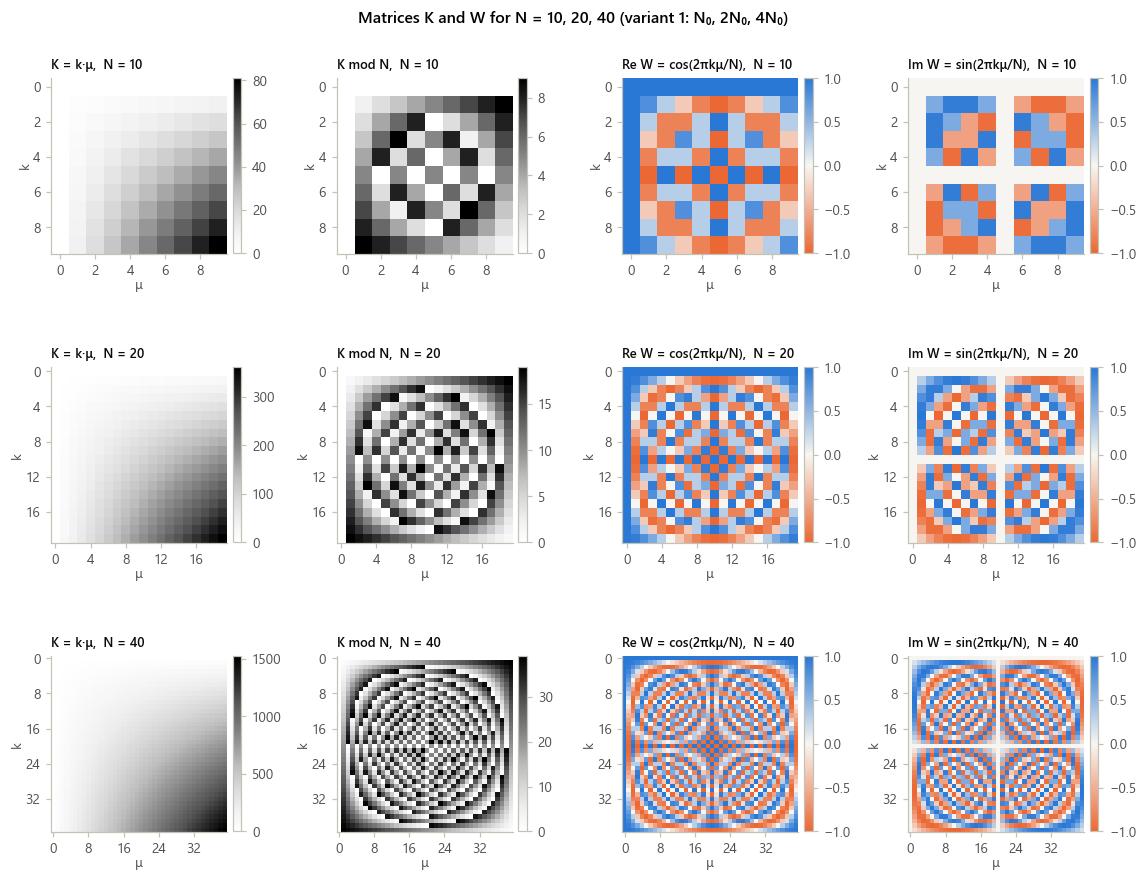

In [12]:
N_PLOT = (10, 20, 40)
fig, axs = plt.subplots(len(N_PLOT), 4, figsize=(10.5, 8.3))
for r, N in enumerate(N_PLOT):
    K, W = build_K(N), build_W(N)
    panels = [(K, "K = k·μ", "Greys", None, None), (K % N, "K mod N", "Greys", 0, N - 1),
              (W.real, "Re W = cos(2πkμ/N)", DIVERGING, -1, 1), (W.imag, "Im W = sin(2πkμ/N)", DIVERGING, -1, 1)]
    for c, (M, ttl, cmap, vmin, vmax) in enumerate(panels):
        ax = axs[r, c]
        im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
        ax.grid(False)
        ax.set_title(f"{ttl},  N = {N}", fontsize=8.5)
        ax.set_xlabel("μ", labelpad=1)
        ax.set_ylabel("k", labelpad=1)
        ticks = np.arange(0, N, max(1, N//5))
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle("Matrices K and W for N = 10, 20, 40 (variant 1: N₀, 2N₀, 4N₀)")
fig.tight_layout()
save(fig, "fig02_K_W_structure")

## 6. Synthesis for all variants and several N

Every variant is synthesized with x_k = (1/N)·W·x_μ for N = N₀, 2N₀ and 4N₀ (zero-padded spectrum). Each result
is checked against `numpy.fft.ifft`, against the inverse operation (DFT x_μ = W*·x_k must return the
coefficients) and against Parseval's theorem Σ|x[k]|² = (1/N)·Σ|X[μ]|².

In [13]:
N_FACTORS = (1, 2, 4)
SIG = {}                                  # (variant, N) -> x_k
rows = []
for no, X0 in VARIANTS.items():
    for m in N_FACTORS:
        N = m*X0.size
        X = pad(X0, N)
        x = idft_matrix(X)
        SIG[(no, N)] = x
        kneg = (-np.arange(N)) % N
        rows.append({
            "No": no, "N": N,
            "= ifft": np.allclose(x, ifft(X)),
            "W*·x_k = x_μ": np.allclose(dft_matrix(x), X),
            "Parseval": np.isclose(np.sum(np.abs(x)**2), np.sum(np.abs(X)**2)/N),
            "x[−k] = x*[k]": np.allclose(x[kneg], np.conj(x)),
            "argmax|x| = 0": int(np.argmax(np.abs(x))) == 0,
            "x[0] = ΣX/N": np.isclose(x[0], X.sum()/N),
            "mean = X[0]/N": np.isclose(x.mean(), X[0]/N),
            "max|Im x|": np.abs(x.imag).max(),
        })
CHK = pd.DataFrame(rows)
bool_cols = ["= ifft", "W*·x_k = x_μ", "Parseval", "x[−k] = x*[k]", "argmax|x| = 0", "x[0] = ΣX/N", "mean = X[0]/N"]
summary = CHK[bool_cols].all().to_frame("holds for all 15 variants × 3 values of N")
display(summary)
assert summary.iloc[:, 0].all()
assert (CHK["max|Im x|"] > 0.1).all()          # every synthesized signal is complex

# identical vectors -> identical signals
for g, nos in GROUPS.items():
    for no in nos[1:]:
        for m in N_FACTORS:
            N = m*VARIANTS[no].size
            assert np.array_equal(SIG[(no, N)], SIG[(nos[0], N)])
print("Identical results within every group G1–G9: OK")

,holds for all 15 variants × 3 values of N
= ifft,True
W*·x_k = x_μ,True
Parseval,True
x[−k] = x*[k],True
argmax|x| = 0,True
x[0] = ΣX/N,True
mean = X[0]/N,True


Identical results within every group G1–G9: OK


**The synthesized signals for N = N₀** (real and imaginary part of x[k], 3 decimals):

In [14]:
cols = pd.Index(range(max(N0_SET)), name="k")
re_tab = pd.DataFrame({no: pd.Series(clean(SIG[(no, X.size)].real)) for no, X in VARIANTS.items()}).T
im_tab = pd.DataFrame({no: pd.Series(clean(SIG[(no, X.size)].imag)) for no, X in VARIANTS.items()}).T
for tab in (re_tab, im_tab):
    tab.index.name = "No"
    tab.columns = cols
print("Re x[k], N = N₀:")
display(re_tab.fillna(""))
print("Im x[k], N = N₀:")
display(im_tab.fillna(""))

key = pd.DataFrame([{
    "No": no, "group": GROUP_OF[no], "N": N,
    "x[0] = ΣX/N": SIG[(no, N)][0].real, "DC = mean(x) = X[0]/N": SIG[(no, N)].mean().real,
    "max|x[k]|": np.abs(SIG[(no, N)]).max(), "energy Σ|x|²": np.sum(np.abs(SIG[(no, N)])**2),
} for no, X in VARIANTS.items() for N in (X.size*m for m in N_FACTORS)]).set_index(["No", "N"])
print("Key quantities for N = N₀, 2N₀, 4N₀:")
display(key)

Re x[k], N = N₀:


k,0,1,2,3,4,5,6,7,8,9,10,11,12
No,,,,,,,,,,,,,
1,2.400,-0.031,0.719,0.081,0.831,0.400,0.831,0.081,0.719,-0.031,,,
2,3.462,0.332,0.821,0.330,0.348,1.072,0.366,0.366,1.072,0.348,0.33,0.821,0.332
3,2.400,-0.031,0.719,0.081,0.831,0.400,0.831,0.081,0.719,-0.031,,,
4,2.667,-0.192,0.887,0.167,0.805,0.805,0.167,0.887,-0.192,,,,
5,2.818,-0.026,0.672,0.027,0.716,0.202,0.202,0.716,0.027,0.672,-0.026,,
6,2.500,0.069,0.819,0.181,0.931,0.500,0.931,0.181,0.819,0.069,,,
7,3.200,0.138,1.009,0.362,-0.109,0.000,-0.109,0.362,1.009,0.138,,,
8,2.500,-0.062,0.638,0.162,0.862,0.300,0.862,0.162,0.638,-0.062,,,
9,2.700,0.212,0.812,-0.012,0.588,0.100,0.588,-0.012,0.812,0.212,,,


Im x[k], N = N₀:


k,0,1,2,3,4,5,6,7,8,9,10,11,12
No,,,,,,,,,,,,,
1,0.0,1.018,-0.131,0.159,-0.213,0.000,0.213,-0.159,0.131,-1.018,,,
2,0.0,1.091,0.869,-0.125,0.074,0.104,0.061,-0.061,-0.104,-0.074,0.125,-0.869,-1.091
3,0.0,1.018,-0.131,0.159,-0.213,0.000,0.213,-0.159,0.131,-1.018,,,
4,0.0,0.831,0.154,-0.289,0.188,-0.188,0.289,-0.154,-0.831,,,,
5,0.0,1.158,0.257,-0.077,0.320,-0.089,0.089,-0.320,0.077,-0.257,-1.158,,
6,0.0,1.018,-0.131,0.159,-0.213,0.000,0.213,-0.159,0.131,-1.018,,,
7,0.0,0.923,0.833,0.218,0.778,0.000,-0.778,-0.218,-0.833,-0.923,,,
8,0.0,1.114,-0.190,0.100,-0.118,0.000,0.118,-0.100,0.190,-1.114,,,
9,0.0,1.195,0.154,0.445,-0.036,0.000,0.036,-0.445,-0.154,-1.195,,,


Key quantities for N = N₀, 2N₀, 4N₀:


group  x[0] = ΣX/N  DC = mean(x) = X[0]/N  max|x[k]|  energy Σ|x|²
No N                                                                    
1  10    G1        2.400                  0.600      2.400        10.600
   20    G1        1.200                  0.300      1.200         5.300
   40    G1        0.600                  0.150      0.600         2.650
2  13    G2        3.462                  0.769      3.462        20.538
   26    G2        1.731                  0.385      1.731        10.269
   52    G2        0.865                  0.192      0.865         5.135
3  10    G1        2.400                  0.600      2.400        10.600
   20    G1        1.200                  0.300      1.200         5.300
   40    G1        0.600                  0.150      0.600         2.650
4  9     G3        2.667                  0.667      2.667        11.778
   18    G3        1.333                  0.333      1.333         5.889
   36    G3        0.667                  0.167      0.667         2.944
5  11    G4        2.818                  0.545      2.818        13.000
   22    G4        1.409                  0.273      1.409         6.500
   44    G4        0.705                  0.136      0.705         3.250
6  10    G5        2.500                  0.700      2.500        11.900
   20    G5        1.250                  0.350      1.250         5.950
   40    G5        0.625                  0.175      0.625         2.975
7  10    G6        3.200                  0.600      3.200        17.000
   20    G6        1.600                  0.300      1.600         8.500
   40    G6        0.800                  0.150      0.800         4.250
8  10    G7        2.500                  0.600      2.500        11.300
   20    G7        1.250                  0.300      1.250         5.650
   40    G7        0.625                  0.150      0.625         2.825
9  10    G8        2.700                  0.600      2.700        12.700
   20    G8        1.350                  0.300      1.350         6.350
   40    G8        0.675                  0.150      0.675         3.175
10 10    G9        2.300                  0.600      2.300         9.700
   20    G9        1.150                  0.300      1.150         4.850
   40    G9        0.575                  0.150      0.575         2.425
11 10    G1        2.400                  0.600      2.400        10.600
   20    G1        1.200                  0.300      1.200         5.300
   40    G1        0.600                  0.150      0.600         2.650
12 13    G2        3.462                  0.769      3.462        20.538
   26    G2        1.731                  0.385      1.731        10.269
   52    G2        0.865                  0.192      0.865         5.135
13 10    G1        2.400                  0.600      2.400        10.600
   20    G1        1.200                  0.300      1.200         5.300
   40    G1        0.600                  0.150      0.600         2.650
14 9     G3        2.667                  0.667      2.667        11.778
   18    G3        1.333                  0.333      1.333         5.889
   36    G3        0.667                  0.167      0.667         2.944
15 11    G4        2.818                  0.545      2.818        13.000
   22    G4        1.409                  0.273      1.409         6.500
   44    G4        0.705                  0.136      0.705         3.250

## 7. Plots of the synthesized signals

One figure per group G1–G9 (the title lists the variants it covers). Each figure shows the synthesized signal for
N = N₀, 2N₀ and 4N₀: real part (blue) and imaginary part (orange) as stems, |x[k]| as a thin grey line.
Connecting samples by a line is used only for |x[k]| and only for visual convenience.

In [15]:
def plot_group(g):
    nos = GROUPS[g]
    X0 = VARIANTS[nos[0]]
    vec = ", ".join(f"{v:g}" for v in X0)
    fig, axs = plt.subplots(1, len(N_FACTORS), figsize=(10.5, 3.0), sharey=True,
                            gridspec_kw={"width_ratios": [1, 1.4, 2.2]})
    for ax, m in zip(axs, N_FACTORS):
        N = m*X0.size
        x = SIG[(nos[0], N)]
        k = np.arange(N)
        ms = 4.0 if N <= 26 else 2.6
        ax.plot(k, np.abs(x), "-", color=MUTED, lw=0.8, zorder=1, label="|x[k]|")
        stem(ax, k, x.real, C_RE, "Re x[k]", ms=ms)
        stem(ax, k, x.imag, C_IM, "Im x[k]", ms=ms)
        ax.set_title(f"N = {N}" + (" (= N₀)" if m == 1 else f" (= {m}N₀)"))
        ax.set_xlabel("sample k")
        ax.set_xlim(-0.8, N - 0.2)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    axs[0].set_ylabel("x[k]")
    axs[-1].legend(loc="upper right", ncols=3)
    fig.suptitle(f"{g} — variant{'s' if len(nos) > 1 else ''} {', '.join(map(str, nos))}:  x_μ = [{vec}]ᵀ",
                 x=0.01, ha="left")
    fig.tight_layout()
    save(fig, f"fig{2 + int(g[1:]):02d}_{g}_variants_{'_'.join(map(str, nos))}")

### 7.1 G1 — variants 1, 3, 11, 13

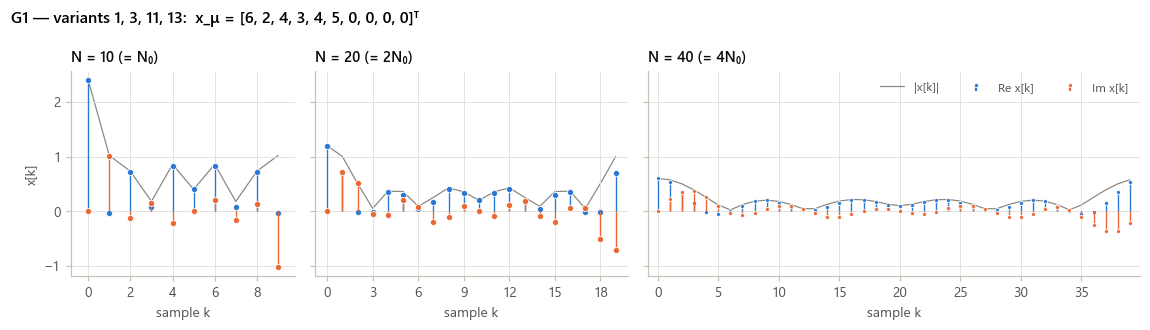

In [16]:
plot_group("G1")

### 7.2 G2 — variants 2, 12

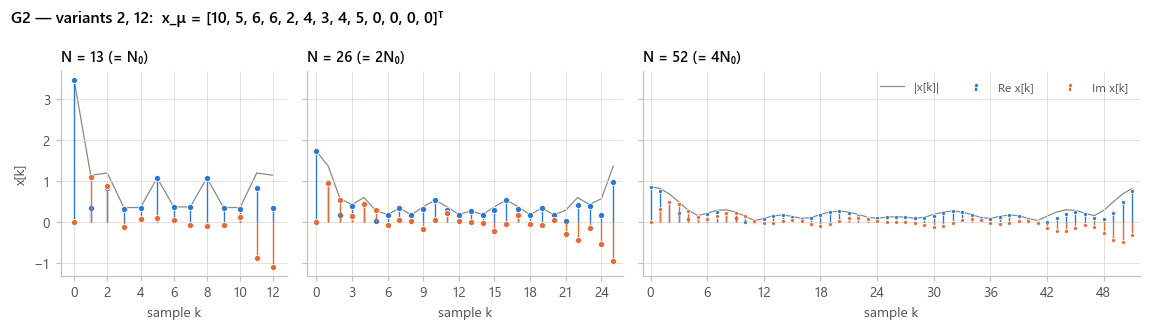

In [17]:
plot_group("G2")

### 7.3 G3 — variants 4, 14

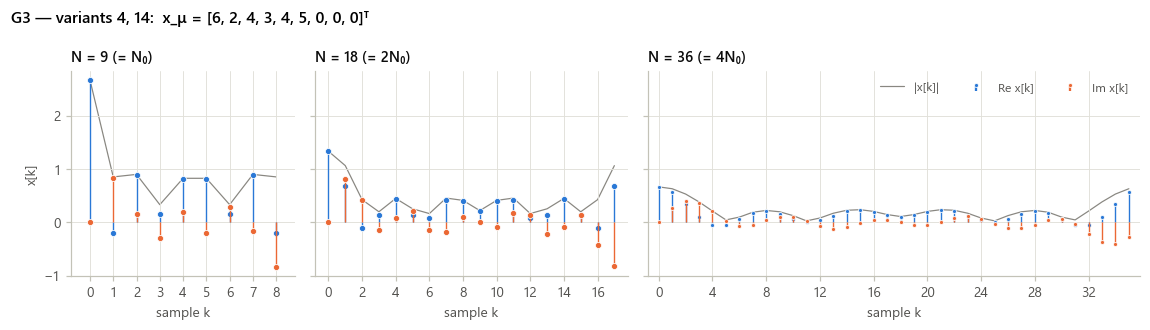

In [18]:
plot_group("G3")

### 7.4 G4 — variants 5, 15

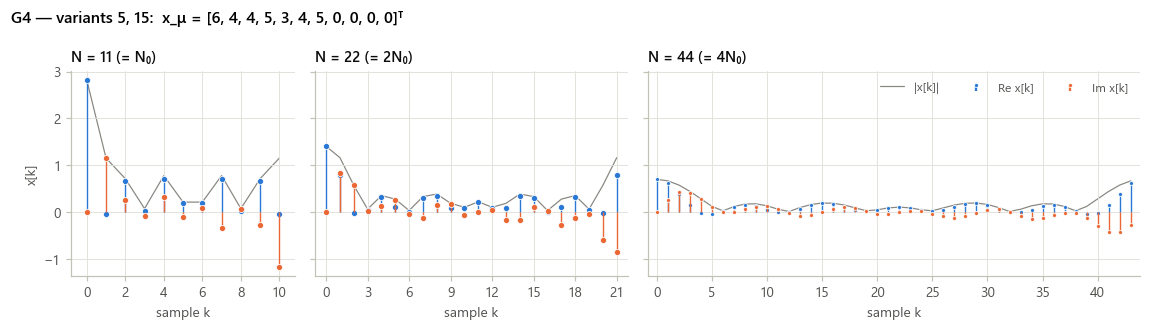

In [19]:
plot_group("G4")

### 7.5 G5 — variant 6

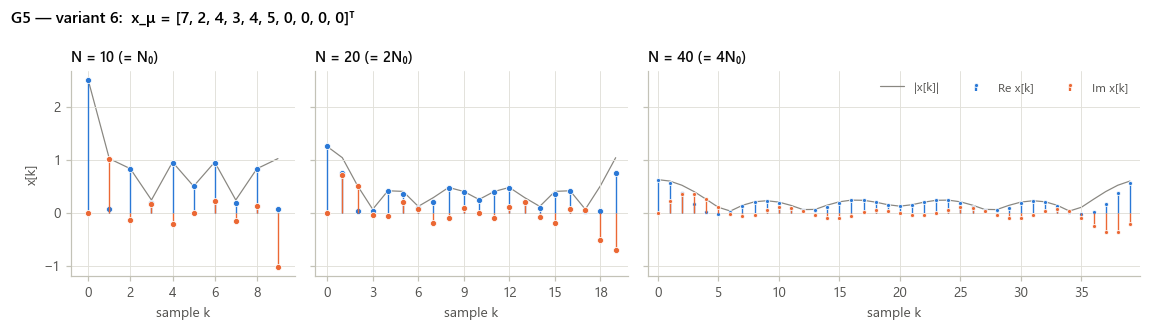

In [20]:
plot_group("G5")

### 7.6 G6 — variant 7

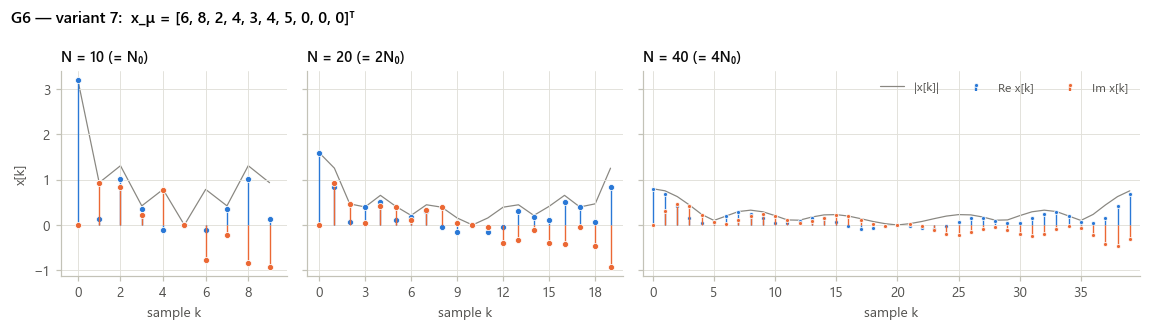

In [21]:
plot_group("G6")

### 7.7 G7 — variant 8

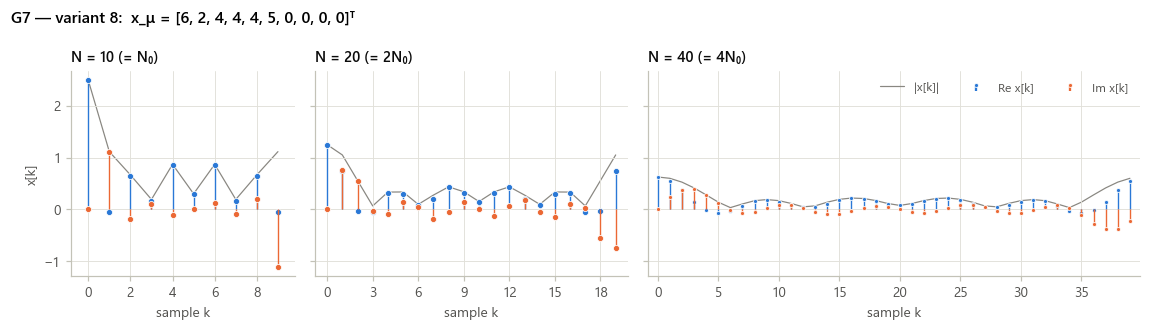

In [22]:
plot_group("G7")

### 7.8 G8 — variant 9

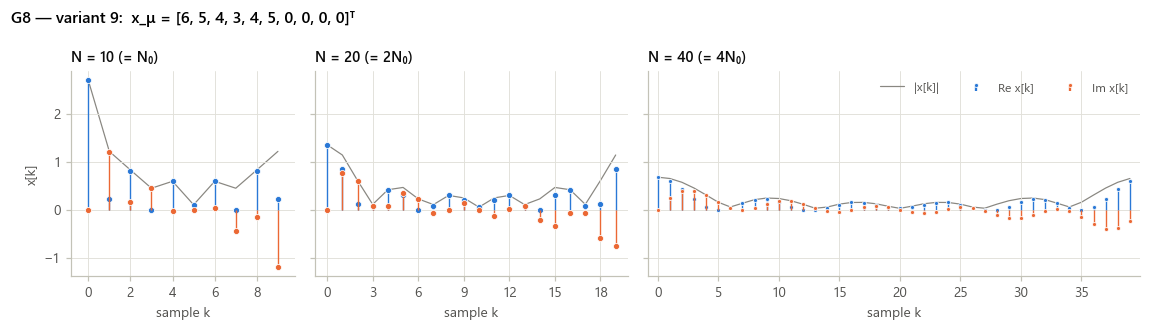

In [23]:
plot_group("G8")

### 7.9 G9 — variant 10

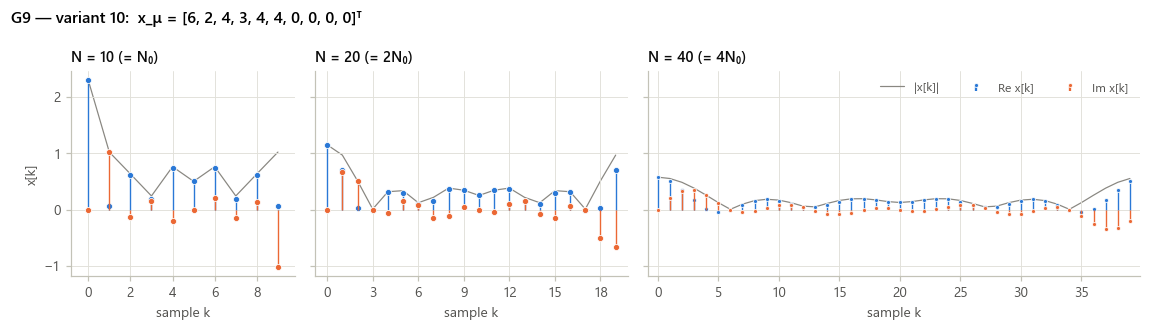

In [24]:
plot_group("G9")

### 7.10 The synthesized signal as a linear combination of eigensignals (variant 1, N = 10)

x_k = (1/N)·W·x_μ = Σ_μ (X[μ]/N)·w_μ: each non-zero coefficient contributes one column of W, i.e. one complex
exponential with μ periods in N samples, scaled by X[μ]/N. The last panel shows that the sum of the six
contributions equals the IDFT result.

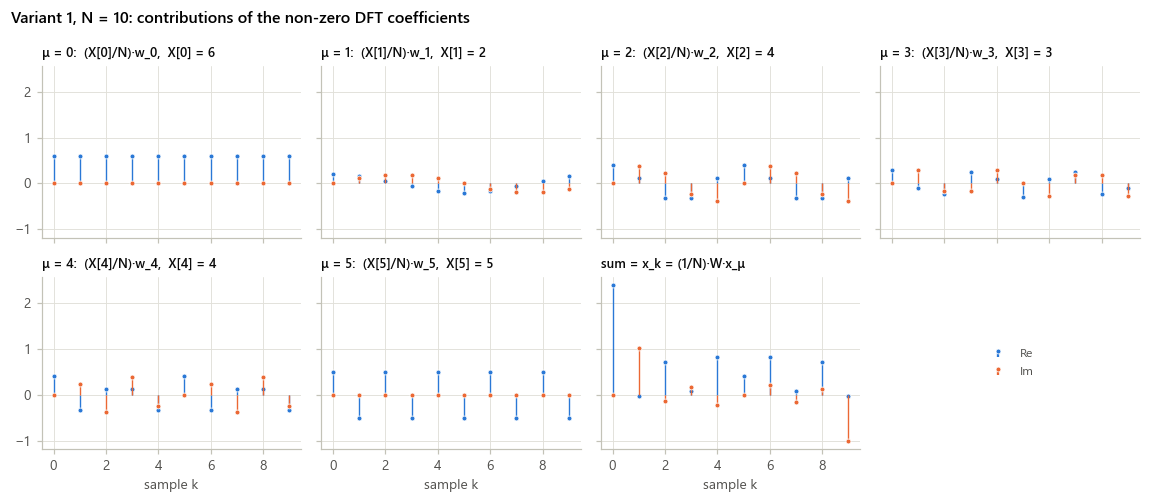

In [25]:
X1, N1 = VARIANTS[1], VARIANTS[1].size
W10 = build_W(N1)
k1 = np.arange(N1)
contrib = [X1[mu]/N1 * W10[:, mu] for mu in range(N1) if X1[mu] != 0]
assert np.allclose(np.sum(contrib, axis=0), SIG[(1, N1)])
fig, axs = plt.subplots(2, 4, figsize=(10.5, 4.6), sharex=True, sharey=True)
for ax, mu in zip(axs.flat, np.flatnonzero(X1)):
    c = X1[mu]/N1 * W10[:, mu]
    stem(ax, k1, c.real, C_RE, "Re", ms=3.2)
    stem(ax, k1, c.imag, C_IM, "Im", ms=3.2)
    ax.set_title(f"μ = {mu}:  (X[{mu}]/N)·w_{mu},  X[{mu}] = {X1[mu]:g}", fontsize=8.5)
ax = axs.flat[len(contrib)]
x1 = SIG[(1, N1)]
stem(ax, k1, x1.real, C_RE, "Re", ms=3.2)
stem(ax, k1, x1.imag, C_IM, "Im", ms=3.2)
ax.set_title("sum = x_k = (1/N)·W·x_μ", fontsize=8.5)
axs.flat[-1].axis("off")
axs.flat[-1].legend(*axs.flat[0].get_legend_handles_labels(), loc="center")
for ax in axs[-1]:
    ax.set_xlabel("sample k")
fig.suptitle("Variant 1, N = 10: contributions of the non-zero DFT coefficients", x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig12_eigensignal_decomposition_V1")

## 8. Effect of N

With zero-padding, x[k] = (1/N)·Σ_μ X[μ]·e^(j2πμk/N) = (1/N)·P(k/N), where P(t) = Σ_μ X[μ]·e^(j2πμt) is a
periodic trigonometric polynomial (period 1) that does not depend on N. Increasing N therefore **samples the same
periodic function more densely** (N samples per period) and scales the amplitude by 1/N. The figure shows P(t)
(lines) and the scaled samples N·x[k] at t = k/N for N = N₀ (circles) and N = 4N₀ (dots) for all nine groups.

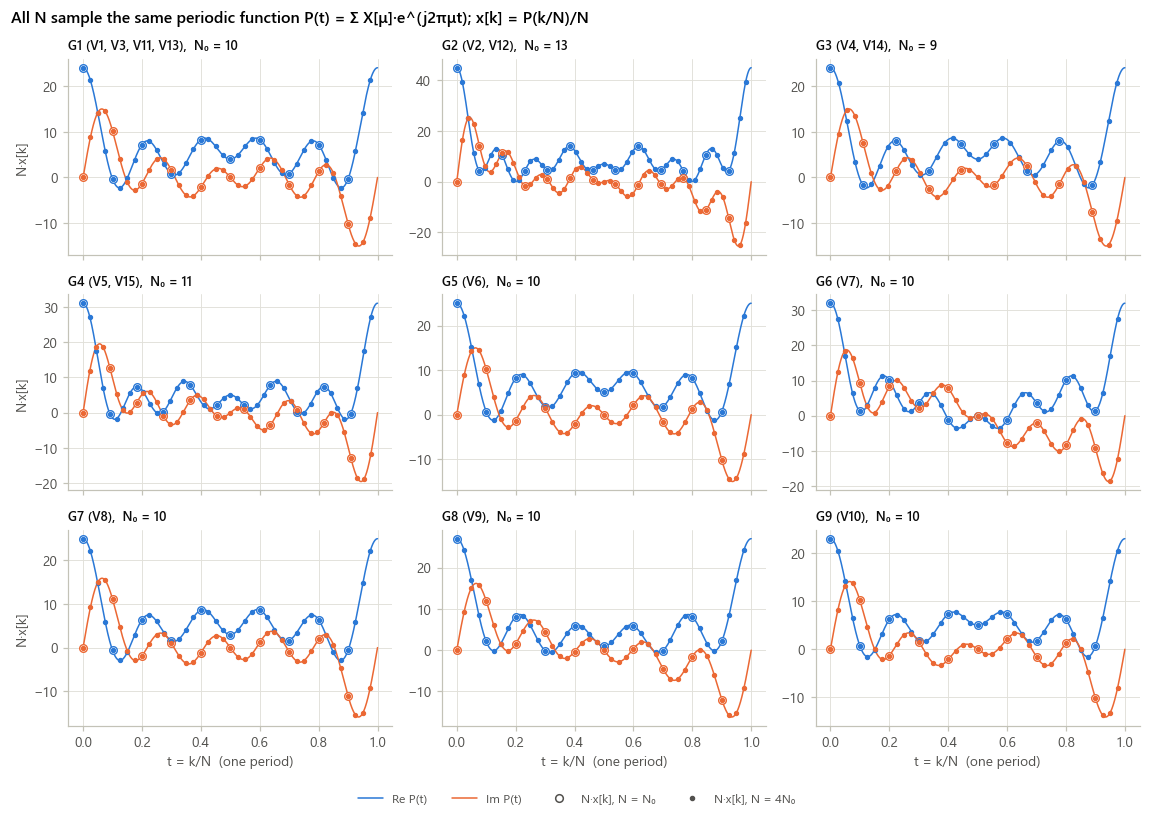

In [26]:
t = np.linspace(0, 1, 2001)
fig, axs = plt.subplots(3, 3, figsize=(10.5, 7.4), sharex=True)
for ax, (g, nos) in zip(axs.flat, GROUPS.items()):
    X0 = VARIANTS[nos[0]]
    mu = np.arange(X0.size)
    P = np.exp(1j*2*np.pi*np.outer(t, mu)) @ X0
    ax.plot(t, P.real, color=C_RE, lw=1.0, label="Re P(t)")
    ax.plot(t, P.imag, color=C_IM, lw=1.0, label="Im P(t)")
    for m, ms, mk in ((1, 5.0, "o"), (4, 2.6, "o")):
        N = m*X0.size
        xN = N*SIG[(nos[0], N)]
        tk = np.arange(N)/N
        assert np.allclose(xN, np.exp(1j*2*np.pi*np.outer(tk, mu)) @ X0)   # samples lie on P(t)
        face = "white" if m == 1 else None
        ax.plot(tk, xN.real, mk, ms=ms, color=C_RE, mfc=face or C_RE, mew=0.9)
        ax.plot(tk, xN.imag, mk, ms=ms, color=C_IM, mfc=face or C_IM, mew=0.9)
    ax.set_title(f"{g} (V{', V'.join(map(str, nos))}),  N₀ = {X0.size}", fontsize=8.5)
for ax in axs[-1]:
    ax.set_xlabel("t = k/N  (one period)")
for ax in axs[:, 0]:
    ax.set_ylabel("N·x[k]")
h = [plt.Line2D([], [], color=C_RE, lw=1), plt.Line2D([], [], color=C_IM, lw=1),
     plt.Line2D([], [], ls="", marker="o", color=INK2, mfc="white", ms=5),
     plt.Line2D([], [], ls="", marker="o", color=INK2, ms=2.6)]
fig.legend(h, ["Re P(t)", "Im P(t)", "N·x[k], N = N₀", "N·x[k], N = 4N₀"], loc="lower center", ncols=4,
           bbox_to_anchor=(0.5, -0.01))
fig.suptitle("All N sample the same periodic function P(t) = Σ X[μ]·e^(j2πμt); x[k] = P(k/N)/N",
             x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "fig13_effect_of_N")

In [27]:
# Same non-zero coefficients, different N0: G1 (N0 = 10) and G3 (N0 = 9) sample the same P(t)
g1, g3 = VARIANTS[1], VARIANTS[4]
assert np.array_equal(g1[:6], g3[:6]) and not g1[6:].any() and not g3[6:].any()
assert np.allclose(10*SIG[(1, 10)][0], 9*SIG[(4, 9)][0])
print(f"x[0]: variant 1 (N = 10) = {SIG[(1, 10)][0].real:.3f},  variant 4 (N = 9) = {SIG[(4, 9)][0].real:.3f};  "
      f"N·x[0] = ΣX = {g1.sum():g} for both")
print("x[0] of variant 1 for N = 10, 20, 40:", [round(float(SIG[(1, N)][0].real), 3) for N in (10, 20, 40)])

x[0]: variant 1 (N = 10) = 2.400,  variant 4 (N = 9) = 2.667;  N·x[0] = ΣX = 24 for both
x[0] of variant 1 for N = 10, 20, 40: [2.4, 1.2, 0.6]


## 9. Interpretation

**Is x[k] real or complex?** Complex, for every variant and every N (max |Im x[k]| > 0.1 everywhere). A real
signal requires a Hermitian-symmetric spectrum X[μ] = X*[(N − μ) mod N]; here all coefficients above μ = 8 are
zero while X[1] … X[8] are not, so the symmetry is violated. The signals contain only the "positive-frequency"
complex exponentials e^(+j2πμk/N), which rotate counter-clockwise — a sum of cosines in the real part and of sines
in the imaginary part.

**Structure of the signal.** Because all X[μ] are real, x[(−k) mod N] = x*[k]: the real part is circularly even and
the imaginary part circularly odd (Im x[0] = 0, and Im x[N/2] = 0 for even N), which is visible in every plot.
All coefficients are non-negative, so all exponentials are in phase at k = 0: x[0] = ΣX[μ]/N is real and is the
maximum of |x[k]| (e.g. 24/10 = 2.4 for variant 1). The DC value is mean(x) = X[0]/N, and the energy satisfies
Parseval's theorem. Each signal is the linear combination (1/N)·Σ X[μ]·w_μ of the eigensignals (columns of W),
Section 7.10.

**How does N change the signal?** Appending zeros to x_μ does not add new components; it only changes the
frequency grid: index μ now corresponds to Ω_μ = 2πμ/N, i.e. μ periods in N samples. The synthesized signal is
the same periodic function P(t) sampled with N points per period and scaled by 1/N (Section 8): for N = 2N₀ and
4N₀ the signal looks smoother and "slower" (more samples per period) and its amplitude halves with every doubling
of N (x[0] of variant 1: 2.4 → 1.2 → 0.6). With N = N₀ the signal is sampled so coarsely that its shape is hard to
recognize; the trailing zeros in the given vectors only decide the IDFT length N₀ (variants 1 and 4 have the same
non-zero coefficients and sample the same P(t) with 10 and 9 points).

**K and W.** K and W depend only on N (four pairs for N = N₀ cover all variants). W is symmetric, its columns are
orthogonal and W⁻¹ = W*/N, so the matrix IDFT is exactly invertible by the matrix DFT and agrees with
`numpy.fft.ifft` to machine precision.

## 10. Conclusions

1. The IDFT was implemented in matrix notation x_k = (1/N)·W·x_μ with W = e^(+j2π/N ⊙ K) and K = outer(k, μ),
   validated against eq. (10), the example of Sec. 6 and `numpy.fft.ifft`.
2. All 15 variants (9 different vectors) were synthesized for N = N₀, 2N₀ and 4N₀; K and W are shown for all
   N₀ ∈ {9, 10, 11, 13}, and the synthesized signals are plotted for every variant.
3. The synthesized signals are complex, because the given spectra are not Hermitian-symmetric; their real part is
   even, their imaginary part odd, and the maximum |x[0]| = ΣX/N occurs at k = 0.
4. Increasing N by zero-padding the spectrum samples the same periodic signal more densely and scales it by 1/N;
   it does not change the frequency content.